### Approach

For an approximately rectangular field, short side = area / long side.
We convert hectares to m² and fit linear regression using the long and
estimated short sides, with an intercept.

We use declared dimensions only, excluding the on-site hedge measurement
and the post-survey fencing quote.

In [39]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

df = pd.read_csv("fry-ndship/data/potato_fields.csv")

In [40]:
df["short_m"] = df["area_ha"] * 10_000 / df["long_side_m"]
X = sm.add_constant(df[["long_side_m", "short_m"]])
res = sm.OLS(df["edge_m"], X).fit()

print("R²:", res.rsquared)
print(res.params)

R²: 0.9983673004221523
const         -0.000348
long_side_m    1.900000
short_m        1.899994
dtype: float64


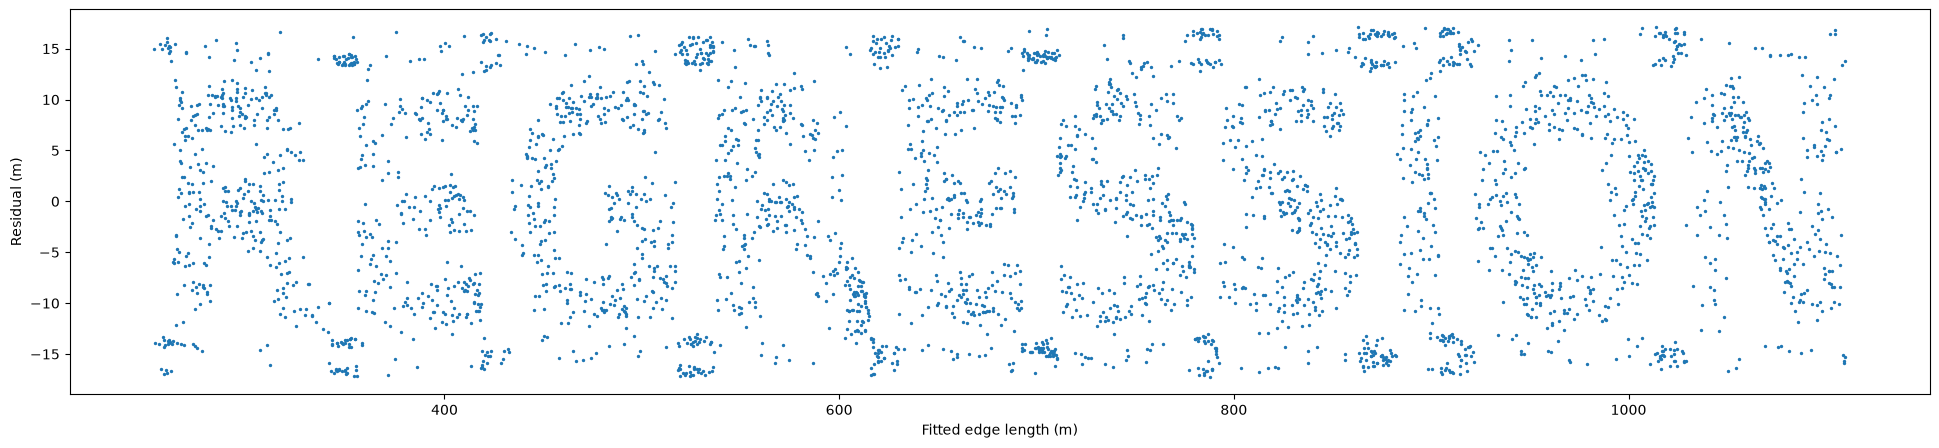

In [41]:
plt.figure(figsize=(24, 5))
plt.scatter(res.fittedvalues, res.resid, s=2)
plt.xlabel("Fitted edge length (m)")
plt.ylabel("Residual (m)")
plt.savefig("fry-ndship/figures/residuals.png",
            dpi=150, bbox_inches="tight")
plt.show()

### Result

The model explains approximately 99.84% of the variation in edge length,
but the residuals plotted against fitted values spell **REGRESSION**.

Flag: `SIGMOID_REGRESSION`

A high R² can still hide meaningful patterns in the residuals.